In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Configuración central del experimento y la red neuronal.
RANDOM_STATE = 42
DATA_PATH = Path("..") / "Cliente.csv"
MODEL_CONFIG = {
    "hidden_layer_sizes": (64, 32),
    "dropout_rates": (0.25, 0.15),
    "learning_rate": 0.001,
    "batch_size": 32,
    "epochs": 150,
    "validation_split": 0.15,
    "early_stopping_patience": 15,
    "reduce_lr_factor": 0.5,
    "reduce_lr_patience": 5,
    "min_learning_rate": 1e-6,
    "classification_threshold": 0.5,
}

tf.keras.utils.set_random_seed(RANDOM_STATE)

df = pd.read_csv(DATA_PATH)
df = df.drop(columns=["customerID"])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

print(f"Filas: {df.shape[0]}, columnas: {df.shape[1]}")
print(f"Valores faltantes en TotalCharges: {df['TotalCharges'].isna().sum()}")
print(df["Churn"].value_counts(normalize=True).rename({0: "No", 1: "Yes"}))

Filas: 7043, columnas: 20
Valores faltantes en TotalCharges: 11
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


## Red neuronal para predecir `Churn`

Se separan los datos en entrenamiento y prueba de forma estratificada. El preprocesamiento queda dentro del pipeline para que los imputadores, el escalado y el one-hot encoding se ajusten solamente con el conjunto de entrenamiento.

In [3]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

numeric_features = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [
    column for column in X.columns if column not in numeric_features
]

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features),
    ]
)

X_train_processed = preprocessor.fit_transform(X_train).astype("float32")
X_test_processed = preprocessor.transform(X_test).astype("float32")

class_weight = {
    0: 1.0,
    1: float((y_train == 0).sum() / (y_train == 1).sum()),
}

hidden_units = MODEL_CONFIG["hidden_layer_sizes"]
dropout_rates = MODEL_CONFIG["dropout_rates"]
model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=(X_train_processed.shape[1],)),
        tf.keras.layers.Dense(hidden_units[0], activation="relu"),
        tf.keras.layers.Dropout(dropout_rates[0]),
        tf.keras.layers.Dense(hidden_units[1], activation="relu"),
        tf.keras.layers.Dropout(dropout_rates[1]),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ],
    name="red_neuronal_churn",
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=MODEL_CONFIG["learning_rate"]
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ],
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=MODEL_CONFIG["early_stopping_patience"],
    restore_best_weights=True,
)
reduce_learning_rate = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=MODEL_CONFIG["reduce_lr_factor"],
    patience=MODEL_CONFIG["reduce_lr_patience"],
    min_lr=MODEL_CONFIG["min_learning_rate"],
)

history = model.fit(
    X_train_processed,
    y_train,
    validation_split=MODEL_CONFIG["validation_split"],
    epochs=MODEL_CONFIG["epochs"],
    batch_size=MODEL_CONFIG["batch_size"],
    class_weight=class_weight,
    callbacks=[early_stopping, reduce_learning_rate],
    verbose=0,
)

print(f"Épocas realizadas: {len(history.history['loss'])}")
print(f"Mejor val_auc: {max(history.history['val_auc']):.3f}")
print(f"Evaluación en prueba: {model.evaluate(X_test_processed, y_test, verbose=0)}")

Épocas realizadas: 20
Mejor val_auc: 0.812
Evaluación en prueba: [0.5081360936164856, 0.7324343323707581, 0.837784469127655, 0.49751242995262146, 0.8021390438079834]


Reporte de clasificación:
              precision    recall  f1-score   support

 No abandona      0.908     0.707     0.795      1035
    Abandona      0.498     0.802     0.614       374

    accuracy                          0.732      1409
   macro avg      0.703     0.755     0.705      1409
weighted avg      0.799     0.732     0.747      1409

ROC-AUC: 0.838


Text(0.5, 1.0, 'Matriz de confusión - Churn')

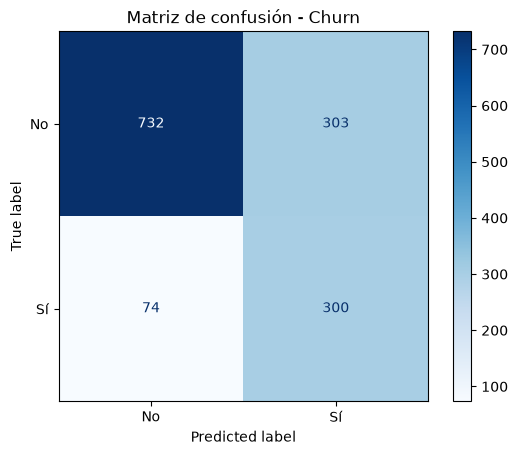

In [4]:
y_proba = model.predict(X_test_processed, verbose=0).ravel()
y_pred = (y_proba >= MODEL_CONFIG["classification_threshold"]).astype(int)

print("Reporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No abandona", "Abandona"],
        digits=3,
    )
)
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.3f}")

confusion_matrix_display = ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No", "Sí"],
    cmap="Blues",
)
confusion_matrix_display.ax_.set_title("Matriz de confusión - Churn")

## Predicción para un cliente nuevo

La función devuelve la probabilidad estimada de abandono. El umbral predeterminado es `0.5`; puede reducirse si la prioridad es detectar más clientes en riesgo, aceptando más falsas alarmas.

In [12]:
def predecir_abandono(cliente, umbral=0.5):
    cliente = pd.DataFrame([cliente]).drop(columns=["customerID"], errors="ignore")
    cliente_processed = preprocessor.transform(cliente).astype("float32")
    probabilidad_abandono = float(model.predict(cliente_processed, verbose=0)[0, 0])
    prediccion = int(probabilidad_abandono >= umbral)
    return {
        "probabilidad_abandono": round(probabilidad_abandono, 3),
        "prediccion": "Abandona" if prediccion else "No abandona",
    }

cliente_ejemplo = X_test.iloc[0].to_dict()
print(predecir_abandono(cliente_ejemplo))

{'probabilidad_abandono': 0.133, 'prediccion': 'No abandona'}
